# 02 · Features

Este notebook justifica las **features derivadas** que se agregan a la OBT y las **columnas que se excluyen**. Toda la preparación vive en `src/pipeline.py` (`construir_preparacion`), y este notebook la importa en vez de copiarla.

| Feature derivada | Origen | Cálculo |
|---|---|---|
| `log_amt` | Hallazgo de la EDA: monto con cola larga (asimetría 41,9) | `log(1 + amt)` |
| `amt_sobre_p95_categoria` | Hallazgo de la EDA: el fraude se concentra en montos altos **para su categoría**; es la misma lógica de la regla fija del banco | `amt / p95(amt de su categoría)`, con el p95 **aprendido solo en el `fit`** |
| `hora_sin`, `hora_cos` | Hallazgo de la EDA: el fraude se concentra entre 22:00 y 03:59 | Codificación cíclica de la hora: 23 h y 0 h quedan cerca |
| `log_segundos_desde_anterior` | Cola larga del tiempo entre compras | `log(1 + segundos)`; nulo en la 1.ª compra del cliente (se imputa con un indicador) |

Para probar que aportan, cada una se evalúa por **ablación**: la misma CV temporal, con y sin la feature (sección 3).

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

from datos import cargar_obt, metadatos_snapshot
from pipeline import (EXCLUIDAS, ENTRADA, NUMERICAS_OBT, BINARIAS, CATEGORICAS, TODAS_DERIVADAS, DERIVADAS_FINALES, SEMILLA,
                      MontoSobreP95Categoria, agregar_features, construir_preparacion, construir_modelo,
                      dividir, CVTemporalSubmuestreada, evaluar_cv)

DOCS = Path.cwd().parent / "docs" / "features"
DOCS.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(DOCS / nombre, dpi=120); plt.close(fig)
    display(Image(filename=str(DOCS / nombre)))

print("snapshot sha256:", metadatos_snapshot()["sha256"])
df = cargar_obt()
X_ent, y_ent, X_pru, y_pru, ent, pru = dividir(df)
print("entrenamiento:", X_ent.shape, "| prueba:", X_pru.shape, "| entradas del modelo:", len(ENTRADA))

snapshot sha256: 9be410f73fb8c090e7647fc27559665c28431d29a0652548d16d8b932d9e9bce


entrenamiento: (1326733, 21) | prueba: (525661, 21) | entradas del modelo: 21


## 1. Columnas de la OBT que no entran al modelo

In [2]:
excl = pd.DataFrame({"columna": list(EXCLUIDAS), "motivo": list(EXCLUIDAS.values())})
excl.to_csv(DOCS / "columnas_excluidas.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(excl)
print("Entradas del modelo:", ENTRADA)

,columna,motivo
0,trans_num,identificador de la transacción
1,trans_ts,marca de tiempo: se usa solo para ordenar y dividir
2,fecha,fecha calendario: el modelo debe generalizar a fechas futuras
3,anio,año: no se repite en el futuro (2019/2020)
4,mes,mes: prueba (jul-dic) y entrenamiento cubren meses distintos del ciclo
5,particion_temporal,define la división entrenamiento/prueba
6,source_file,"archivo de origen de Kaggle: correlaciona con la partición, no con el fraude"
7,cliente_sk,identificador del cliente (memorizaría clientes)
8,comercio_sk,identificador del comercio
9,categoria_sk,clave sustituta (la categoría entra como texto)


Entradas del modelo: ['amt', 'distancia_km', 'edad_en_transaccion', 'city_pop', 'n_tx_1h', 'gasto_1h', 'n_tx_24h', 'gasto_24h', 'n_tx_previas', 'monto_medio_previo', 'monto_relativo', 'hora', 'dia_semana', 'es_nocturna', 'es_fin_de_semana', 'es_menor_de_edad', 'es_multicategoria', 'categoria', 'canal', 'state', 'segundos_desde_anterior']


**Fuga de información:** se excluyen los identificadores (`trans_num`, `cliente_sk`, `comercio_sk`), la fecha y las variables que definen la partición (`fecha`, `anio`, `mes`, `particion_temporal`) y **`source_file`**. Esta última delata el archivo de Kaggle (train o test), que coincide con el período y con un cambio de prevalencia, no con el fraude. Tampoco entran `unix_time` (quedó fuera de la OBT por su desfase de ~7 años, ver PSet 2), los nombres ni la calle.

Las ventanas de comportamiento (`n_tx_1h`, `gasto_24h`, `segundos_desde_anterior`, `monto_relativo`…) **se calcularon en el PSet 2 solo con transacciones anteriores** del mismo cliente: `rangeBetween(-86400, -1)` y filas estrictamente previas, verificado en 5.000 de 5.000 filas con un recálculo en SQL. Están disponibles en el momento de la autorización.

## 2. Evidencia descriptiva de cada feature derivada (entrenamiento)

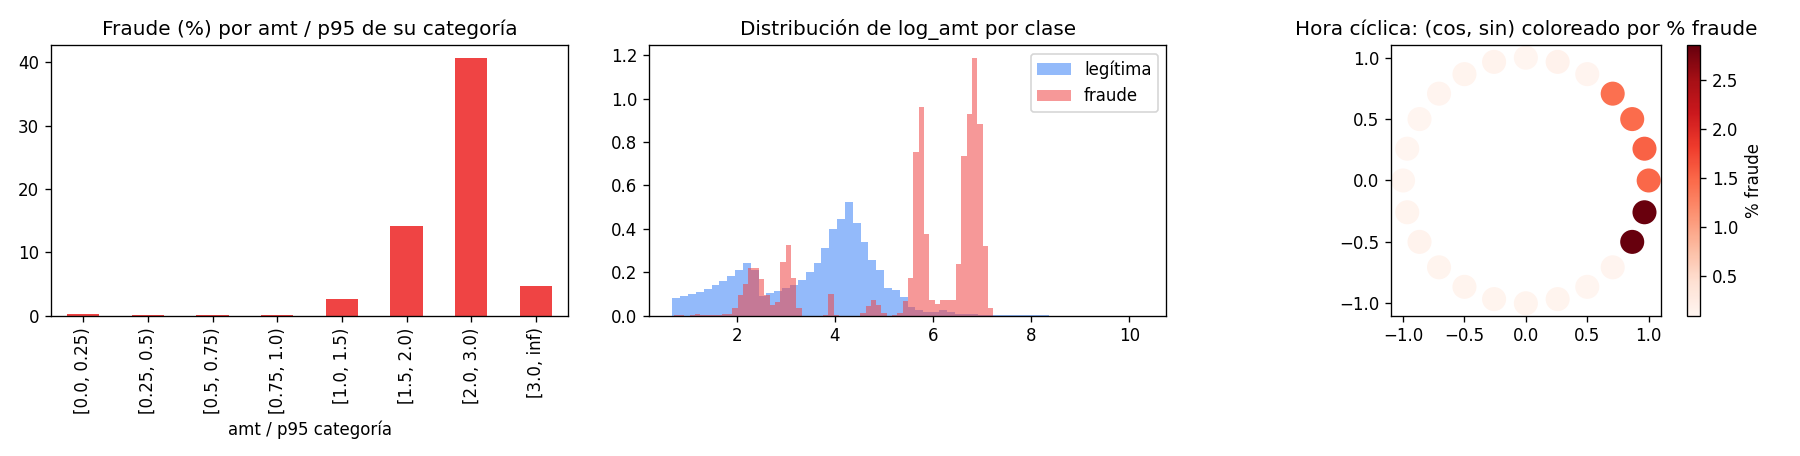

,transacciones,tasa_fraude_pct
tramo,,
"[0.0, 0.25)",615930,0.262
"[0.25, 0.5)",307616,0.019
"[0.5, 0.75)",226355,0.011
"[0.75, 1.0)",110480,0.112
"[1.0, 1.5)",46250,2.681
"[1.5, 2.0)",9950,14.201
"[2.0, 3.0)",7478,40.653
"[3.0, inf)",2674,4.675


In [3]:
F = agregar_features(X_ent)
p95 = MontoSobreP95Categoria().fit(X_ent[["amt", "categoria"]])
F["amt_sobre_p95_categoria"] = p95.transform(X_ent[["amt", "categoria"]]).ravel()
F[OBJ := "is_fraud"] = y_ent.values

bins = [0, .25, .5, .75, 1, 1.5, 2, 3, np.inf]
t1 = (F.assign(tramo=pd.cut(F["amt_sobre_p95_categoria"], bins, right=False))
        .groupby("tramo", observed=True)[OBJ].agg(transacciones="size", tasa_fraude="mean"))
t1["tasa_fraude_pct"] = (100 * t1["tasa_fraude"]).round(3)
t1.drop(columns="tasa_fraude").to_csv(DOCS / "fraude_por_amt_sobre_p95.csv")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
t1["tasa_fraude_pct"].plot.bar(ax=ax[0], color="#ef4444"); ax[0].set_title("Fraude (%) por amt / p95 de su categoría")
ax[0].set_xlabel("amt / p95 categoría")
for k, color in ((0, "#3b82f6"), (1, "#ef4444")):
    ax[1].hist(F.loc[F[OBJ] == k, "log_amt"], bins=60, density=True, alpha=.55, color=color, label=["legítima", "fraude"][k])
ax[1].legend(); ax[1].set_title("Distribución de log_amt por clase")
g = F.groupby(["hora_sin", "hora_cos"])[OBJ].mean().reset_index()
sc = ax[2].scatter(g["hora_cos"], g["hora_sin"], c=100 * g[OBJ], cmap="Reds", s=180)
fig.colorbar(sc, ax=ax[2], label="% fraude"); ax[2].set_title("Hora cíclica: (cos, sin) coloreado por % fraude"); ax[2].set_aspect("equal")
guardar(fig, "evidencia_features_derivadas.png")
t1.drop(columns="tasa_fraude")

## 3. Ablación: ¿cada feature derivada mejora la CV?

Mismo esquema de validación que el resto del PSet (`CVTemporalSubmuestreada`: `TimeSeriesSplit(3)`, ajuste con todos los fraudes y el 5 % de las legítimas, validación con todas las filas del pliegue) y misma métrica, **AUC-PR**.

- **Regresión logística** (modelo lineal): es sensible a la escala y a la forma de las variables. Aquí es donde `log_amt`, la hora cíclica y el log del tiempo deberían notarse.
- **HistGradientBoosting:** un árbol es invariante a transformaciones monótonas, así que `log_amt` no le cambia nada. Sí puede beneficiarse de `amt_sobre_p95_categoria`, porque resume una interacción monto × categoría.

Una mejora solo cuenta si es **mayor que la desviación entre pliegues**.

In [4]:
cv = CVTemporalSubmuestreada()
modelos = {"logistica": lambda: LogisticRegression(max_iter=1000, random_state=SEMILLA),
           "hist_gb": lambda: HistGradientBoostingClassifier(random_state=SEMILLA)}
variantes = {"sin derivadas": (), "todas las derivadas": TODAS_DERIVADAS}
for d in TODAS_DERIVADAS:
    variantes[f"todas menos {d}"] = tuple(x for x in TODAS_DERIVADAS if x != d)
filas = []
for nombre_m, fabrica in modelos.items():
    for nombre_v, deriv in variantes.items():
        t0 = time.perf_counter()
        r = evaluar_cv(construir_modelo(fabrica(), derivadas=deriv), X_ent, y_ent, cv)
        filas.append({"modelo": nombre_m, "variante": nombre_v, "cv_auc_pr_media": r["cv_auc_pr_media"],
                      "cv_auc_pr_std": r["cv_auc_pr_std"], "segundos": time.perf_counter() - t0,
                      **{f"pliegue_{k}": v for k, v in enumerate(r["pliegues"]["auc_pr_validacion"])}})
        print(f"{nombre_m:10s} {nombre_v:45s} AUC-PR {r['cv_auc_pr_media']:.4f} ± {r['cv_auc_pr_std']:.4f}")
abl = pd.DataFrame(filas)
ref = abl[abl["variante"] == "todas las derivadas"].set_index("modelo")["cv_auc_pr_media"]
abl["delta_vs_todas"] = abl["cv_auc_pr_media"] - abl["modelo"].map(ref)
abl.to_csv(DOCS / "ablacion_features.csv", index=False)
abl.round(4)

logistica  sin derivadas                                 AUC-PR 0.4821 ± 0.0297


logistica  todas las derivadas                           AUC-PR 0.4958 ± 0.0169


logistica  todas menos log_amt                           AUC-PR 0.4776 ± 0.0280


logistica  todas menos hora_ciclica                      AUC-PR 0.4960 ± 0.0174


logistica  todas menos log_segundos_desde_anterior       AUC-PR 0.4954 ± 0.0171


logistica  todas menos amt_sobre_p95_categoria           AUC-PR 0.4840 ± 0.0173


... (3 outputs left out)

hist_gb    todas menos hora_ciclica                      AUC-PR 0.9612 ± 0.0163


hist_gb    todas menos log_segundos_desde_anterior       AUC-PR 0.9579 ± 0.0147


hist_gb    todas menos amt_sobre_p95_categoria           AUC-PR 0.9572 ± 0.0179


,modelo,variante,cv_auc_pr_media,cv_auc_pr_std,segundos,pliegue_0,pliegue_1,pliegue_2,delta_vs_todas
0,logistica,sin derivadas,0.4821,0.0297,4.6305,0.4511,0.4730,0.5221,-0.0137
1,logistica,todas las derivadas,0.4958,0.0169,4.2235,0.5007,0.4731,0.5135,0.0000
2,logistica,todas menos log_amt,0.4776,0.0280,4.1283,0.4491,0.4681,0.5156,-0.0182
3,logistica,todas menos hora_ciclica,0.4960,0.0174,3.7109,0.5001,0.4729,0.5150,0.0003
4,logistica,todas menos log_segundos_desde_anterior,0.4954,0.0171,4.5884,0.5002,0.4725,0.5135,-0.0004
5,logistica,todas menos amt_sobre_p95_categoria,0.4840,0.0173,4.3108,0.4793,0.4655,0.5072,-0.0118
6,hist_gb,sin derivadas,0.9549,0.0182,17.9751,0.9299,0.9622,0.9726,-0.0054
7,hist_gb,todas las derivadas,0.9603,0.0156,19.7631,0.9388,0.9669,0.9753,0.0000
8,hist_gb,todas menos log_amt,0.9603,0.0156,19.4822,0.9388,0.9669,0.9753,0.0000
9,hist_gb,todas menos hora_ciclica,0.9612,0.0163,19.1284,0.9386,0.9691,0.9760,0.0009


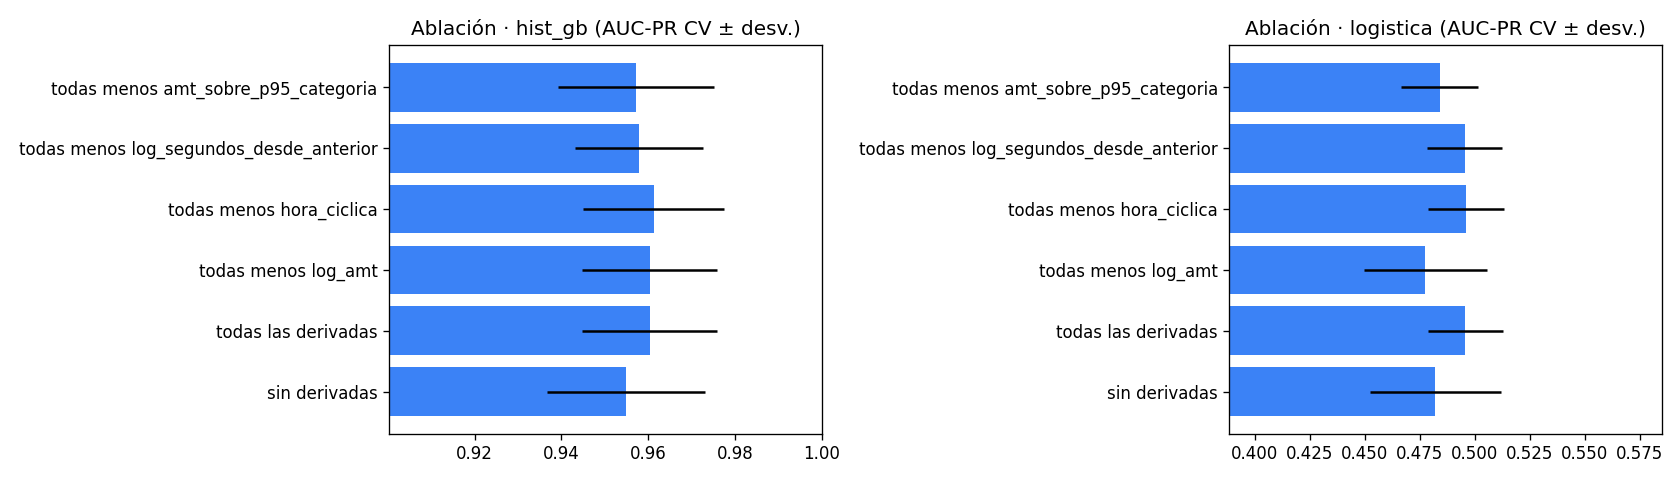

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (m, g) in zip(axes, abl.groupby("modelo")):
    ax.barh(g["variante"], g["cv_auc_pr_media"], xerr=g["cv_auc_pr_std"], color="#3b82f6")
    ax.set_xlim(g["cv_auc_pr_media"].min() - 3 * g["cv_auc_pr_std"].max(), min(1, g["cv_auc_pr_media"].max() + 3 * g["cv_auc_pr_std"].max()))
    ax.set_title(f"Ablación · {m} (AUC-PR CV ± desv.)")
guardar(fig, "ablacion_features.png")

In [6]:
# Conclusión automática por feature: aporte = AUC-PR(todas) - AUC-PR(todas menos la feature)
concl = []
for m in modelos:
    g = abl[abl["modelo"] == m].set_index("variante")
    base = g.loc["todas las derivadas"]
    for d in TODAS_DERIVADAS:
        sin = g.loc[f"todas menos {d}"]
        aporte = base["cv_auc_pr_media"] - sin["cv_auc_pr_media"]
        umbral_ruido = max(base["cv_auc_pr_std"], sin["cv_auc_pr_std"])
        concl.append({"modelo": m, "feature": d, "aporte_auc_pr": aporte, "desv_pliegues": umbral_ruido,
                      "veredicto": "aporta (> desv.)" if aporte > umbral_ruido else ("no se distingue del ruido" if aporte > -umbral_ruido else "empeora")})
concl = pd.DataFrame(concl)
concl.to_csv(DOCS / "aporte_por_feature.csv", index=False)
concl.round(4)

,modelo,feature,aporte_auc_pr,desv_pliegues,veredicto
0,logistica,log_amt,0.0182,0.0280,no se distingue del ruido
1,logistica,hora_ciclica,-0.0003,0.0174,no se distingue del ruido
2,logistica,log_segundos_desde_anterior,0.0004,0.0171,no se distingue del ruido
3,logistica,amt_sobre_p95_categoria,0.0118,0.0173,no se distingue del ruido
4,hist_gb,log_amt,0.0000,0.0156,no se distingue del ruido
5,hist_gb,hora_ciclica,-0.0009,0.0163,no se distingue del ruido
6,hist_gb,log_segundos_desde_anterior,0.0024,0.0156,no se distingue del ruido
7,hist_gb,amt_sobre_p95_categoria,0.0032,0.0179,no se distingue del ruido


**Comparación pareada por pliegue.** Los tres pliegues tienen dificultades distintas (la AUC-PR cambia entre pliegues para *todas* las variantes), y comparar contra la desviación mezcla esa variación con el efecto de la feature. La comparación pareada evalúa la diferencia **dentro del mismo pliegue**: si una feature mejora en los 3 pliegues, el efecto es consistente aunque sea pequeño.

In [7]:
pl = [c for c in abl.columns if c.startswith("pliegue_")]
par = []
for m in modelos:
    g = abl[abl["modelo"] == m].set_index("variante")[pl]
    comparaciones = [("todas las derivadas vs sin derivadas", "todas las derivadas", "sin derivadas")]
    comparaciones += [(f"aporte de {d}", "todas las derivadas", f"todas menos {d}") for d in TODAS_DERIVADAS]
    for nombre, a_, b_ in comparaciones:
        dif = g.loc[a_] - g.loc[b_]
        par.append({"modelo": m, "comparacion": nombre, **{f"delta_{c}": v for c, v in dif.items()},
                    "delta_medio": dif.mean(), "pliegues_que_mejora": int((dif > 0).sum())})
par = pd.DataFrame(par)
par.to_csv(DOCS / "ablacion_pareada_por_pliegue.csv", index=False)
par.round(4)

,modelo,comparacion,delta_pliegue_0,delta_pliegue_1,delta_pliegue_2,delta_medio,pliegues_que_mejora
0,logistica,todas las derivadas vs sin derivadas,0.0496,0.0000,-0.0086,0.0137,2
1,logistica,aporte de log_amt,0.0516,0.0050,-0.0021,0.0182,2
2,logistica,aporte de hora_ciclica,0.0006,0.0001,-0.0015,-0.0003,2
3,logistica,aporte de log_segundos_desde_anterior,0.0005,0.0005,0.0000,0.0004,3
4,logistica,aporte de amt_sobre_p95_categoria,0.0214,0.0076,0.0063,0.0118,3
5,hist_gb,todas las derivadas vs sin derivadas,0.0089,0.0047,0.0027,0.0054,3
6,hist_gb,aporte de log_amt,0.0000,0.0000,0.0000,0.0000,0
7,hist_gb,aporte de hora_ciclica,0.0002,-0.0022,-0.0007,-0.0009,1
8,hist_gb,aporte de log_segundos_desde_anterior,0.0011,0.0029,0.0033,0.0024,3
9,hist_gb,aporte de amt_sobre_p95_categoria,0.0064,0.0015,0.0015,0.0032,3


**Conclusión de la ablación (cifras de las tablas de arriba):**

| Feature | Logística | HistGB | Decisión |
|---|---|---|---|
| `amt_sobre_p95_categoria` (de la EDA) | mejora en **3 de 3** pliegues (Δ medio +0,0118) | mejora en **3 de 3** (Δ +0,0032) | **Se queda**: es la de efecto más consistente |
| `log_segundos_desde_anterior` | 3 de 3 (Δ +0,0004) | **3 de 3** (Δ +0,0024) | **Se queda** |
| `log_amt` (de la EDA) | 2 de 3 (Δ medio +0,0182, el mayor en el lineal) | 0 (los árboles son invariantes al log) | **Se queda**: ayuda al modelo lineal y no afecta a los árboles |
| `hora_sin` / `hora_cos` | Δ −0,0003 | 1 de 3 (Δ −0,0009) | **Se descarta**: `hora` y `es_nocturna` ya capturan la señal nocturna |

Ninguna mejora individual supera la desviación entre pliegues, porque los pliegues difieren mucho en dificultad. Por eso se decide con la comparación **pareada**. Con las cuatro derivadas, HistGB mejora en los 3 pliegues frente a no tener ninguna (Δ medio +0,0054). Al quitar la hora cíclica no se pierde nada, porque no mejoró en ningún modelo. El conjunto final es `DERIVADAS_FINALES` en `src/pipeline.py`. Las features derivadas no compensan que el modelo lineal quede muy por debajo de los árboles (~0,50 frente a ~0,96): la señal está en interacciones no lineales, como ya sugería la EDA.

## 4. Prueba de que no hay fuga en las features derivadas

1. **Disponibilidad en la autorización.** Las features derivadas solo usan columnas de la **propia** transacción, que existen cuando llega la solicitud de autorización: `amt`, `categoria`, `hora` y `segundos_desde_anterior`. Esta última se calcula con la transacción anterior del mismo cliente.
2. **Estado aprendido solo con entrenamiento.** `amt_sobre_p95_categoria` necesita el p95 de cada categoría. Ese valor se aprende en `fit` y queda **dentro del Pipeline**, así que en la CV se recalcula con el bloque de ajuste de cada pliegue, y en la prueba final, solo con el entrenamiento.
3. **Verificación empírica (abajo):**
   - se alteran a propósito los montos del **conjunto de prueba** y se comprueba que la preparación ajustada en entrenamiento produce **exactamente** las mismas features para las filas de entrenamiento;
   - se comprueba que en cada pliegue de la CV el p95 aprendido viene solo de fechas anteriores a la validación.

In [8]:
prep = construir_preparacion(TODAS_DERIVADAS).fit(X_ent)
Z1 = prep.transform(X_ent.head(20_000))
X_pru_alterada = X_pru.assign(amt=X_pru["amt"] * 10)       # la prueba "cambia" por completo
prep2 = construir_preparacion(TODAS_DERIVADAS).fit(X_ent)                  # se vuelve a ajustar solo con entrenamiento
Z2 = prep2.transform(X_ent.head(20_000))
print("Features de entrenamiento idénticas aunque cambie la prueba:", np.array_equal(Z1, Z2))

p95_ent = prep.named_steps["columnas"].named_transformers_["monto_p95_categoria"].named_steps["p95"].p95_
p95_todo = pd.concat([X_ent, X_pru])[["amt", "categoria"]].groupby("categoria")["amt"].quantile(.95)
comp = pd.DataFrame({"p95_aprendido_en_entrenamiento": pd.Series(p95_ent), "p95_si_se_usara_todo_(fuga)": p95_todo}).round(2)
comp.to_csv(DOCS / "p95_categoria_entrenamiento_vs_todo.csv")

for k, (aj, va) in enumerate(cv.split(X_ent, y_ent)):
    print(f"pliegue {k}: ajuste hasta {ent['trans_ts'].iloc[aj].max()} < validación desde {ent['trans_ts'].iloc[va].min()} ->",
          ent['trans_ts'].iloc[aj].max() < ent['trans_ts'].iloc[va].min())
comp

Features de entrenamiento idénticas aunque cambie la prueba: True


pliegue 0: ajuste hasta 2019-06-07 03:47:00 < validación desde 2019-06-07 03:59:52 -> True
pliegue 1: ajuste hasta 2019-10-09 19:54:10 < validación desde 2019-10-09 20:27:10 -> True
pliegue 2: ajuste hasta 2020-02-10 18:45:07 < validación desde 2020-02-10 18:55:40 -> True


,p95_aprendido_en_entrenamiento,p95_si_se_usara_todo_(fuga)
entertainment,183.26,182.91
food_dining,143.74,143.61
gas_transport,90.72,90.79
grocery_net,95.96,96.04
grocery_pos,215.74,214.85
health_fitness,147.25,146.96
home,150.41,150.20
kids_pets,153.91,153.71
misc_net,382.68,377.35
misc_pos,285.27,283.04


## 5. Codificación de las variables categóricas

| Variable | Valores | Codificación | Por qué |
|---|---|---|---|
| `categoria` | 14 | One-hot (`handle_unknown="ignore"`) | Baja cardinalidad y sin orden natural; también se usa para el p95 de `amt_sobre_p95_categoria` |
| `canal` | 3 (en línea / presencial / otro) | One-hot | Igual que la anterior |
| `state` | 51 | One-hot (`handle_unknown="ignore"`) | Cardinalidad manejable; un estado nuevo en producción queda con todo en cero en vez de fallar |
| `es_nocturna`, `es_fin_de_semana`, `es_menor_de_edad`, `es_multicategoria` | 2 | 0/1 | Binarias |
| `comercio` (693), `job` (497) | alta | **Excluidas** | Con one-hot crearían cientos de columnas casi vacías, y con target encoding habría riesgo de memorizar comercios del dataset simulado. La señal del comercio ya entra por la categoría y el canal |

Las numéricas se imputan con la mediana más un **indicador de faltante** (para la 1.ª compra del cliente) y se estandarizan, todo dentro del Pipeline.

In [9]:
nombres = construir_preparacion().fit(X_ent.head(50_000)).get_feature_names_out()   # DERIVADAS_FINALES
print("Derivadas finales:", DERIVADAS_FINALES)
pd.Series(nombres, name="feature").to_csv(DOCS / "features_finales.csv", index=False)
print(f"{len(nombres)} columnas después de la preparación")
print(list(nombres))

Derivadas finales: ('log_amt', 'log_segundos_desde_anterior', 'amt_sobre_p95_categoria')
90 columnas después de la preparación
['amt', 'distancia_km', 'edad_en_transaccion', 'city_pop', 'n_tx_1h', 'gasto_1h', 'n_tx_24h', 'gasto_24h', 'n_tx_previas', 'monto_medio_previo', 'monto_relativo', 'hora', 'dia_semana', 'log_amt', 'log_segundos_desde_anterior', 'missingindicator_monto_medio_previo', 'missingindicator_monto_relativo', 'missingindicator_log_segundos_desde_anterior', 'es_nocturna', 'es_fin_de_semana', 'es_menor_de_edad', 'es_multicategoria', 'categoria_entertainment', 'categoria_food_dining', 'categoria_gas_transport', 'categoria_grocery_net', 'categoria_grocery_pos', 'categoria_health_fitness', 'categoria_home', 'categoria_kids_pets', 'categoria_misc_net', 'categoria_misc_pos', 'categoria_personal_care', 'categoria_shopping_net', 'categoria_shopping_pos', 'categoria_travel', 'canal_en_linea', 'canal_otro', 'canal_presencial', 'state_AK', 'state_AL', 'state_AR', 'state_AZ', 'state_